# 1121 — Squeezing in the heating × dephasing atlas

**Question.** 1113 section 8 (`plot_heating_dephasing_atlas`) finds the best plain Fock state |n⟩ on a heating × dephasing map. Here the search covers squeezed Fock states S(r)|n⟩ with r ∈ {0, 0.2, 0.4, 1.0}. Which (n, r) is best, how much does squeezing buy, and how should this be drawn?

**Proposed view (Figure A).** Keep the 1113 colour for each n and use the shade within that colour for r. This notebook makes that plot, evaluates it, and adds alternatives (Figures B–D). The evaluation is in section 5.

**Conventions.** Same protocol, engine and readout as 1113: prepare S(r)|n⟩, drive D(β) with noise on, instantaneous readout D(±iα), qubit QFI. `squeezed_fock(n, r)` follows the QuantumOptics sign, so r > 0 squeezes the quadrature the readout uses: the noiseless min QCRB scales as e^{−2r} (eq. 33). Squeezing adds energy, ⟨n̂⟩ = n cosh 2r + sinh² r. The comparison is at fixed r, **not at fixed mean phonon number**.

All plots are saved to `plots/1121/squeezed_*.png` and embedded below. Runtime about 20 min on 8 threads (r = 1 needs 141 Fock levels).

In [2]:
using Pkg
Pkg.activate(@__DIR__)                      # this repo's Project.toml / Manifest.toml (same environment as 1113)
ENV["MPLBACKEND"] = "agg"
using LinearAlgebra, Printf
using PyPlot

BLAS.set_num_threads(1)                     # 61–121-level products are faster single-threaded; parallelism is over grid points
println("Julia threads: ", Threads.nthreads(), "   (start Julia with -t auto; 1 thread takes about 8× longer)")

  Activating project at `c:\Users\jewoo\projects\TestJulia`


Julia threads: 8   (start Julia with -t auto; 1 thread takes about 8× longer)


## 1. Closed forms and engine (copied from 1113 sections 1–2)

Unchanged physics. Two additions: `alpha_grid(r)` stretches the α grid by e^r, because the optimal readout grows as α_opt = e^r √y_opt / 2 (eq. 79); and `tail_population` measures how much population reaches the top 5 Fock levels.

In [3]:
# ---- closed forms (1113 section 1): eq. 33 / 74 / 106. Gc, Gh are Γ_c·t_sig and Γ_h·t_sig ----
function laguerre(n::Int, x::Real)
    n == 0 && return 1.0
    Lm, L = 1.0, 1.0 - x
    for k in 1:(n-1)
        Lm, L = L, ((2k + 1 - x) * L - k * Lm) / (k + 1)
    end
    return L
end

function qcrb_theory(α::Real, n::Int; r::Real=0.0, Gc::Real=0.0, Gh::Real=0.0)
    K = Gc - Gh
    decay = exp(-K)
    diffusion = abs(K) < 1e-9 ? (Gc + Gh) : (Gc + Gh) * (1 - decay) / K     # (2n̄+1)(1 − e^{−Γt})
    f = abs(K) < 1e-9 ? 1.0 - K / 4 : (2 / K) * (1 - exp(-K / 2))           # laser-drift factor, eq. 71
    B = diffusion + decay * exp(-2r)                                        # B_var, eq. 107
    L = laguerre(n, 4α^2 * decay * exp(-2r))
    return exp(4α^2 * B) / (16α^2 * f^2 * L^2)
end

# ---- engine (1113 section 2, unchanged) ----
function displace_matrix(ξ::Number, d::Int; pad::Int=2d)
    a = diagm(1 => sqrt.(1:(pad-1)))
    return exp(ξ * a' - conj(ξ) * a)[1:d, 1:d]
end

# S(r)|n> with the QuantumOptics.squeeze(b, r) sign convention (r > 0 improves sensitivity, eq. 33)
function squeezed_fock(n::Int, r::Real, d::Int; pad::Int=2d)
    v = zeros(pad); v[n+1] = 1.0
    if r != 0
        a = diagm(1 => sqrt.(1:(pad-1)))
        v = exp((r / 2) * (a^2 - (a')^2)) * v
    end
    v = v[1:d]
    return v ./ norm(v)
end

# Exact dephasing + cooling + heating map over a fraction `frac` of the exposure, one small matrix per diagonal k.
struct NoiseStep
    E::Vector{Matrix{Float64}}
    diagonal_only::Bool
    mask::Matrix{Float64}
end

function NoiseStep(Gphi::Real, Gc::Real, Gh::Real, frac::Real, d::Int)
    N = d - 1
    mask = [exp(-0.5 * Gphi * frac * (i - j)^2) for i in 1:d, j in 1:d]            # eq. 124 / 145
    (Gc == 0 && Gh == 0) && return NoiseStep(Matrix{Float64}[], true, mask)
    up(j) = j < N ? j + 1.0 : 0.0
    E = Vector{Matrix{Float64}}(undef, d)
    for k in 0:N
        len = N - k + 1
        T = zeros(len, len)
        for i in 1:len
            m = i - 1
            T[i, i] = -0.5 * Gc * (2m + k) - 0.5 * Gh * (up(m) + up(m + k)) - 0.5 * Gphi * k^2
            i < len && (T[i, i+1] = Gc * sqrt((m + 1) * (m + k + 1)))               # cooling, eq. 142
            i > 1 && (T[i, i-1] = Gh * sqrt(m * (m + k)))                           # heating, eq. 143
        end
        E[k+1] = exp(T .* frac)
    end
    return NoiseStep(E, false, mask)
end

function apply_noise!(ρ::Matrix{Float64}, ns::NoiseStep, buf::Vector{Float64})
    if ns.diagonal_only
        ρ .*= ns.mask
        return ρ
    end
    d = size(ρ, 1)
    @inbounds for k in 0:(d-1)
        len = d - k
        Ek = ns.E[k+1]
        for i in 1:len
            s = 0.0
            for j in 1:len
                s += Ek[i, j] * ρ[j, j+k]
            end
            buf[i] = s
        end
        for i in 1:len
            ρ[i, i+k] = buf[i]; ρ[i+k, i] = buf[i]
        end
    end
    return ρ
end

default_steps(Gphi, Gc, Gh) = max(64, ceil(Int, 6 * max(Gphi, Gc, Gh)))

struct Drive
    D::Matrix{Float64}; Dt::Matrix{Float64}; G::Matrix{Float64}
    full::NoiseStep; half::NoiseStep; steps::Int
end

function Drive(β::Real, Gphi::Real, Gc::Real, Gh::Real; steps::Int=default_steps(Gphi, Gc, Gh), d::Int)
    a = diagm(1 => sqrt.(1:(d-1)))
    G = a' - a
    D = exp((β / steps) .* G)
    return Drive(D, Matrix(D'), G, NoiseStep(Gphi, Gc, Gh, 1 / steps, d), NoiseStep(Gphi, Gc, Gh, 0.5 / steps, d), steps)
end

# ρ(β) and ∂ρ/∂β after the noisy drive. Strang split: noise(½)·[drive·noise]^(S−1)·drive·noise(½).
function propagate(ψ0::Vector{Float64}, drv::Drive)
    d = length(ψ0); S = drv.steps
    ρ = ψ0 * ψ0'; dρ = zeros(d, d)
    t1 = similar(ρ); t2 = similar(ρ); buf = zeros(d)
    apply_noise!(ρ, drv.half, buf)
    for s in 1:S
        mul!(t1, drv.D, ρ);  mul!(ρ, t1, drv.Dt)
        mul!(t1, drv.D, dρ); mul!(dρ, t1, drv.Dt)
        mul!(t1, drv.G, ρ);  mul!(t2, ρ, drv.G)
        @. dρ += (t1 - t2) / S
        ns = s == S ? drv.half : drv.full
        apply_noise!(ρ, ns, buf); apply_noise!(dρ, ns, buf)
    end
    return ρ, dρ
end

# eq. 149–150: C = Tr[D(2iα)ρ],  QFI = |∂C|² + Re(C*∂C)² / (1 − |C|²)
function qcrb_from_state(ρ::Matrix{Float64}, dρ::Matrix{Float64}, V::Matrix{ComplexF64})
    C = zero(ComplexF64); dC = zero(ComplexF64)
    @inbounds for j in axes(V, 2), i in axes(V, 1)
        C += V[j, i] * ρ[i, j]; dC += V[j, i] * dρ[i, j]
    end
    qfi = abs2(dC) + real(conj(C) * dC)^2 / max(1 - abs2(C), 1e-300)
    return qfi > 0 ? 1 / qfi : Inf
end

readout_matrices(αs, d::Int) = [displace_matrix(2im * a, d) for a in αs]

# Squeezing stretches the optimal readout by e^r (α_opt = e^r √y_opt / 2, eq. 79), so the α grid is scaled per r.
alpha_grid(r; base=collect(0.05:0.015:2.6)) = base .* exp(r)

tail_population(ρ) = sum(@view ρ[diagind(ρ)[end-4:end]])      # population in the top 5 Fock levels

tail_population (generic function with 1 method)

## 2. Fock cutoff and checks against the closed form

A squeezed Fock state is spread over many number states: ⟨n̂⟩ = n cosh 2r + sinh² r, and its tail falls only as tanh(r)^m. 1113 used 61 levels for every state, which is not enough at r = 1. The truncated S(1)|4⟩ gives a noiseless min QCRB of 0.010, but eq. 33 gives 0.031. A truncation error like this makes a state look **better** than it is, so a "winner" map would be wrong exactly where it matters. The cell below picks the cutoff for each r, then checks the engine against eq. 33 / 106.

In [4]:
# Fock cutoff per squeezing: smallest d (61, 81, ...) where S(r)|n_max> leaves < 1e-10 in the top 5 levels.
# 1113 used d = 61 for every state. That is fine for r ≤ 0.4, but S(1)|4> needs about 141 levels:
# at d = 61 the truncated state gives a fake noiseless min QCRB of 0.010, while eq. 33 gives 0.031.
function cutoff_for(r::Real, n_max::Int; tol=1e-10, ds=61:20:201)
    for d in ds
        ψ = squeezed_fock(n_max, r, d)
        sum(abs2, @view ψ[end-4:end]) < tol && return d
    end
    error("no cutoff up to $(last(ds)) for r = $r, n = $n_max")
end

const N_VALS = collect(0:4)
const R_VALS = [0.0, 0.2, 0.4, 1.0]
const DIMS = Dict(r => cutoff_for(r, maximum(N_VALS)) for r in R_VALS)
println("Fock cutoff per r: ", join(["r = $r → d = $(DIMS[r])" for r in R_VALS], ",  "))
@printf("mean phonon number <n> = n cosh 2r + sinh² r (n = 0 … 4):\n")
for r in R_VALS
    @printf("  r = %.1f: %s\n", r, join([@sprintf("%.2f", n * cosh(2r) + sinh(r)^2) for n in N_VALS], ", "))
end

# Engine vs closed form (eq. 33 / 106) with squeezing, hot bath Γc = Γh, β = 1. Dephasing has no closed form.
println("\nengine vs closed form, min QCRB over α (hot bath Γc = Γh, β = 1)")
@printf("%2s %4s %6s | %10s %10s %9s | %8s\n", "n", "r", "Γh·t", "engine", "eq. 106", "rel diff", "tail")
for r in R_VALS
    d = DIMS[r]; αs = alpha_grid(r; base=collect(0.05:0.005:2.6)); Vs = readout_matrices(αs, d)
    for n in (0, 2, 4), gh in (0.0, 0.1)
    ρ, dρ = propagate(squeezed_fock(n, r, d), Drive(1.0, 0.0, gh, gh; d=d))
    q = minimum(qcrb_from_state(ρ, dρ, V) for V in Vs)
    th = minimum(qcrb_theory(a, n; r=r, Gc=gh, Gh=gh) for a in αs)
    @printf("%2d %4.1f %6.2f | %10.5g %10.5g %+8.1e | %8.1e\n", n, r, gh, q, th, q / th - 1, tail_population(ρ))
    end
end

Fock cutoff per r: r = 0.0 → d = 61,  r = 0.2 → d = 61,  r = 0.4 → d = 61,  r = 1.0 → d = 141
mean phonon number <n> = n cosh 2r + sinh² r (n = 0 … 4):
  r = 0.0: 0.00, 1.00, 2.00, 3.00, 4.00
  r = 0.2: 0.04, 1.12, 2.20, 3.28, 4.36
  r = 0.4: 0.17, 1.51, 2.84, 4.18, 5.52
  r = 1.0: 1.38, 5.14, 8.91, 12.67, 16.43

engine vs closed form, min QCRB over α (hot bath Γc = Γh, β = 1)
 n    r   Γh·t |     engine    eq. 106  rel diff |     tail
 0  0.0   0.00 |    0.67957    0.67957 -6.7e-16 |  5.3e-76
 0  0.0   0.10 |     0.8155     0.8155 +7.2e-14 |  2.6e-14
 2  0.0   0.00 |    0.29606    0.29606 -9.3e-15 |  2.3e-69
 2  0.0   0.10 |     1.1207     1.1207 -3.2e-13 | -3.0e-16
 4  0.0   0.00 |     0.2313     0.2313 +2.7e-15 |  1.5e-63
 4  0.0   0.10 |     1.6074     1.6074 +4.4e-14 | -3.3e-15
 0  0.2   0.00 |    0.45553    0.45553 -4.6e-15 |  1.1e-40
 0  0.2   0.10 |    0.59145    0.59145 +4.7e-14 |  2.7e-14
 2  0.2   0.00 |    0.19845    0.19845 -1.2e-14 |  6.4e-36
 2  0.2   0.10 |    0.98134  

## 3. Atlas over (n, r)

Same axes and bath options as `plot_heating_dephasing_atlas` (1113 section 8), with squeezing added to the search. The default run is the realistic trapped-ion case, a hot bath Γc = Γh at β = 1 (as in 1113 cell 35). A grid point is dropped if any state leaks more than 1e-6 into the top 5 levels. All four figures below come from this one computation.

In [5]:
# Heating (y) × dephasing (x) atlas over Fock number n AND squeezing r. Same axes and bath options as
# plot_heating_dephasing_atlas in 1113 section 8:
#   thermal = true  : Γc = Γh + Gc (real thermal bath; Gc = 0 is the hot-bath limit Γc = Γh, realistic for ions)
#   thermal = false : Γc·t = Gc held fixed while Γh is swept
# Q[k, j, ih, ip] = min over α of the QCRB for n_vals[k], r_vals[j] at heating ghs[ih], dephasing gps[ip].
function squeezed_atlas(; β=1.0, Gc=0.0, thermal=true, n_vals=N_VALS, r_vals=R_VALS, grid=36,
                        gphi_range=(10^-2.5, 1e2), gh_range=(1e-3, 1.0), tail_tol=1e-6)
    gps = 10 .^ range(log10(gphi_range[1]), log10(gphi_range[2]), length=grid)
    ghs = 10 .^ range(log10(gh_range[1]), log10(gh_range[2]), length=grid)
    dims = [get(DIMS, r, cutoff_for(r, maximum(n_vals))) for r in r_vals]
    Vs = [readout_matrices(alpha_grid(r), dims[j]) for (j, r) in enumerate(r_vals)]
    ψs = [squeezed_fock(n, r, dims[j]) for n in n_vals, (j, r) in enumerate(r_vals)]
    Q = fill(NaN, length(n_vals), length(r_vals), grid, grid)
    tails = zeros(length(r_vals), grid, grid)
    t0 = time()
    GC.gc()   # finalize Python (PyPlot) objects on the main thread first: a PyCall finalizer on a worker thread segfaults
    Threads.@threads :dynamic for idx in 1:(grid*grid)
        ih, ip = fldmod1(idx, grid)
        gc = thermal ? ghs[ih] + Gc : Gc
        for (j, d) in enumerate(dims)
            drv = Drive(β, gps[ip], gc, ghs[ih]; d=d)
            for k in eachindex(n_vals)
                ρ, dρ = propagate(ψs[k, j], drv)
                Q[k, j, ih, ip] = minimum(qcrb_from_state(ρ, dρ, V) for V in Vs[j])
                tails[j, ih, ip] = max(tails[j, ih, ip], tail_population(ρ))
            end
        end
    end
    bad = dropdims(maximum(tails, dims=1), dims=1) .> tail_tol      # a point is dropped if any r leaks past its cutoff
    Q[:, :, bad] .= NaN
    label = thermal ? (Gc == 0 ? "hot bath Γc = Γh" : "thermal bath, Γc = Γh + $(Gc)") : "fixed Γc·t = $(Gc)"
    @printf("%s, β = %.2f: %d × %d points × %d states in %.0f s; %d points dropped at the Fock cutoff\n",
            label, β, grid, grid, length(n_vals) * length(r_vals), time() - t0, count(bad))
    return (gps=gps, ghs=ghs, Q=Q, bad=bad, n_vals=n_vals, r_vals=r_vals, β=β, label=label)
end

# Derived maps. "best at fixed r" = min over n; "overall" = min over n and r.
function atlas_maps(at)
    N, R = length(at.n_vals), length(at.r_vals); g1, g2 = size(at.Q, 3), size(at.Q, 4)
    best_r = fill(NaN, R, g1, g2); nstar_r = fill(NaN, R, g1, g2)
    best = fill(NaN, g1, g2); nstar = fill(NaN, g1, g2); rstar = fill(NaN, g1, g2); cls = fill(NaN, g1, g2)
    for i in 1:g1, p in 1:g2
        at.bad[i, p] && continue
        for j in 1:R
            k = argmin(@view at.Q[:, j, i, p])
            best_r[j, i, p] = at.Q[k, j, i, p]; nstar_r[j, i, p] = at.n_vals[k]
        end
        c = argmin(@view at.Q[:, :, i, p])                          # CartesianIndex (k, j)
        best[i, p] = at.Q[c[1], c[2], i, p]; nstar[i, p] = at.n_vals[c[1]]; rstar[i, p] = at.r_vals[c[2]]
        cls[i, p] = (c[1] - 1) * R + c[2]                           # class index for the hue × shade map
    end
    j0 = findfirst(==(0.0), at.r_vals)
    sq_gain = 10 .* log10.(best_r[j0, :, :] ./ best)                # what squeezing buys over the best plain Fock state
    return (best_r=best_r, nstar_r=nstar_r, best=best, nstar=nstar, rstar=rstar, cls=cls, sq_gain=sq_gain, j0=j0)
end

atlas_maps (generic function with 1 method)

In [6]:
at = squeezed_atlas(β=1.0, Gc=0.0, thermal=true)      # realistic hot bath, as in 1113 cell 35 (≈ 18 min on 8 threads)
mp = atlas_maps(at);

hot bath Γc = Γh, β = 1.00: 36 × 36 points × 20 states in 1131 s; 0 points dropped at the Fock cutoff


## 4. Figure A: the proposed view (hue = n, shade = r)

Each Fock number keeps its 1113 colour. Within a colour, lighter means less squeezing and darker means more. A 2-D legend on the right shows every (n, r) swatch and the share of the map it wins.

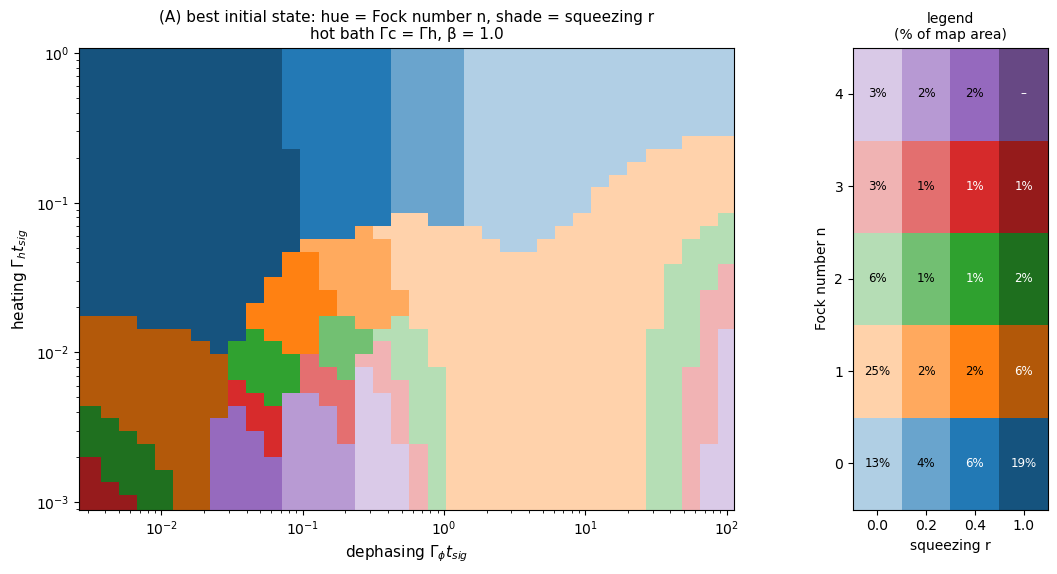

In [7]:
const N_COLORS = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd", "#8c564b", "#e377c2"]   # same n colours as 1113
const mcolors = PyPlot.matplotlib.colors
const PLOT_DIR = joinpath(@__DIR__, "plots", "1121"); mkpath(PLOT_DIR)

# s < 0: blend toward white by |s|;  s > 0: blend toward black by s
function shade(hex, s)
    c = collect(mcolors.to_rgb(hex))
    return Tuple(s < 0 ? c .+ (1 .- c) .* (-s) : c .* (1 - s))
end
shade_steps(R) = R == 1 ? [0.0] : collect(range(-0.65, 0.3, length=R))      # r = 0 lightest … r_max darkest

function setup_axes!(ax, at, ttl)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlabel(L"dephasing $\Gamma_\phi t_{sig}$", fontsize=11); ax.set_ylabel(L"heating $\Gamma_h t_{sig}$", fontsize=11)
    ax.set_title(ttl, fontsize=11)
end

# Figure A: the proposed view. Hue = best n (1113 colours), shade = best r.
function plot_hue_shade(at, mp; file="squeezed_A_hue_shade.png")
    N, R = length(at.n_vals), length(at.r_vals)
    cols = [shade(N_COLORS[k], s) for k in 1:N for s in shade_steps(R)]       # class (k-1)R + j
    fig = figure(figsize=(12.5, 6.0))
    gs = fig.add_gridspec(1, 2, width_ratios=[4.2, 1.25], wspace=0.28)
    ax = fig.add_subplot(gs[1]); lg = fig.add_subplot(gs[2])
    ax.pcolormesh(at.gps, at.ghs, mp.cls, cmap=mcolors.ListedColormap(cols), vmin=0.5, vmax=N * R + 0.5, shading="nearest")
    setup_axes!(ax, at, "(A) best initial state: hue = Fock number n, shade = squeezing r\n$(at.label), β = $(at.β)")
    # 2-D legend: one swatch per (n, r) with its share of the map
    valid = .!isnan.(mp.cls); total = count(valid)
    img = zeros(N, R, 3)
    for k in 1:N, j in 1:R
        img[k, j, :] .= cols[(k-1)*R + j]
    end
    lg.imshow(img, origin="lower", aspect="auto")
    for k in 1:N, j in 1:R
        share = count(==((k - 1) * R + j), mp.cls[valid]) / total
        txt = share == 0 ? "–" : @sprintf("%.0f%%", 100share)
        lum = sum(img[k, j, :] .* [0.299, 0.587, 0.114])
        lg.text(j - 1, k - 1, txt, ha="center", va="center", fontsize=8.5, color=lum < 0.5 ? "white" : "black")
    end
    lg.set_xticks(0:(R-1)); lg.set_xticklabels(string.(at.r_vals)); lg.set_xlabel("squeezing r")
    lg.set_yticks(0:(N-1)); lg.set_yticklabels(string.(at.n_vals)); lg.set_ylabel("Fock number n")
    lg.set_title("legend\n(% of map area)", fontsize=10)
    savefig(joinpath(PLOT_DIR, file), dpi=130, bbox_inches="tight"); display(fig); close(fig)
end

plot_hue_shade(at, mp)

## 5. Evaluation of Figure A, and better views

**What works.** One panel answers "which (n, r) should I prepare here?", and the n colours match the 1113 atlases. Large regions read well: dark blue (vacuum, r = 1) at strong heating and weak dephasing, and pale orange (|1⟩, r = 0) across the dephasing-dominated middle.

**What does not.**

1. **Too many classes.** 5 hues × 4 shades = 20 colours. The eye separates about 6–8 categorical colours. The pale r = 0 shades of different hues (light blue n = 0, light purple n = 4, light pink n = 3) are hard to tell apart where they meet near Γφt ≈ 0.3–1. Neighbouring shades of one hue are hard to judge in absolute terms (is that r = 0.2 or 0.4?).
2. **A winner map hides the margin.** A 0.1 dB win and a 6 dB win get the same flat colour. The squeezing gain is the real question (section 6 finds it is < 0.5 dB on 61% of the map).
3. **Darkness looks like "more of something good".** In Figure A it only means larger r. The physically important feature, that squeezing stops paying once dephasing reaches Γφt ≈ 0.1–1, shows up only as a change from dark to light.
4. **The grid cap shows.** Where squeezing helps, the winner is usually the largest r on the grid (r = 1 wins 27% of the map). That marks the edge of the search, not a physical optimum.

**Better: answer the two questions separately.**

- **Figure B, small multiples.** One best-n map per fixed r, using only the 5 n colours, with the r = 0 boundaries dashed in every panel. It shows how squeezing pushes the Fock boundaries down, toward lower n and lower heating.
- **Figure C, decomposed.** (a) The squeezing gain in dB on a one-hue sequential scale with labelled contours: how much squeezing buys. (b) The best r* on a one-hue ordinal scale, with the best-n regions drawn as labelled lines: which state to prepare.
- **Figure D, line cuts.** Best QCRB versus dephasing at three heating rates, one line per r. Here a light→dark ramp for r works, because the lines are compared along one axis and each is labelled at its end. The crossing points are where more squeezing stops helping.

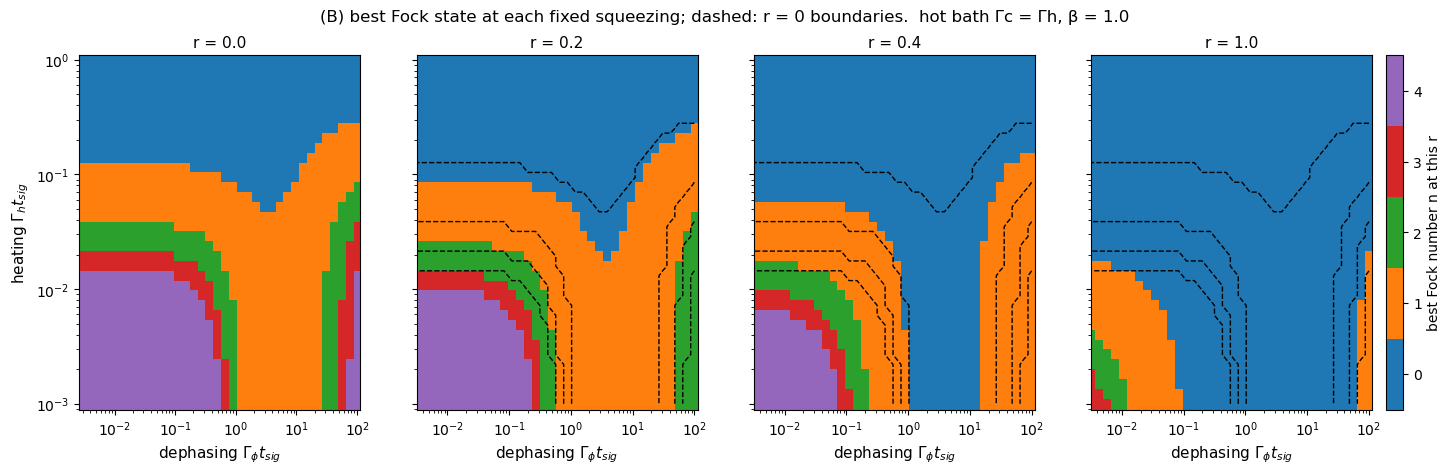

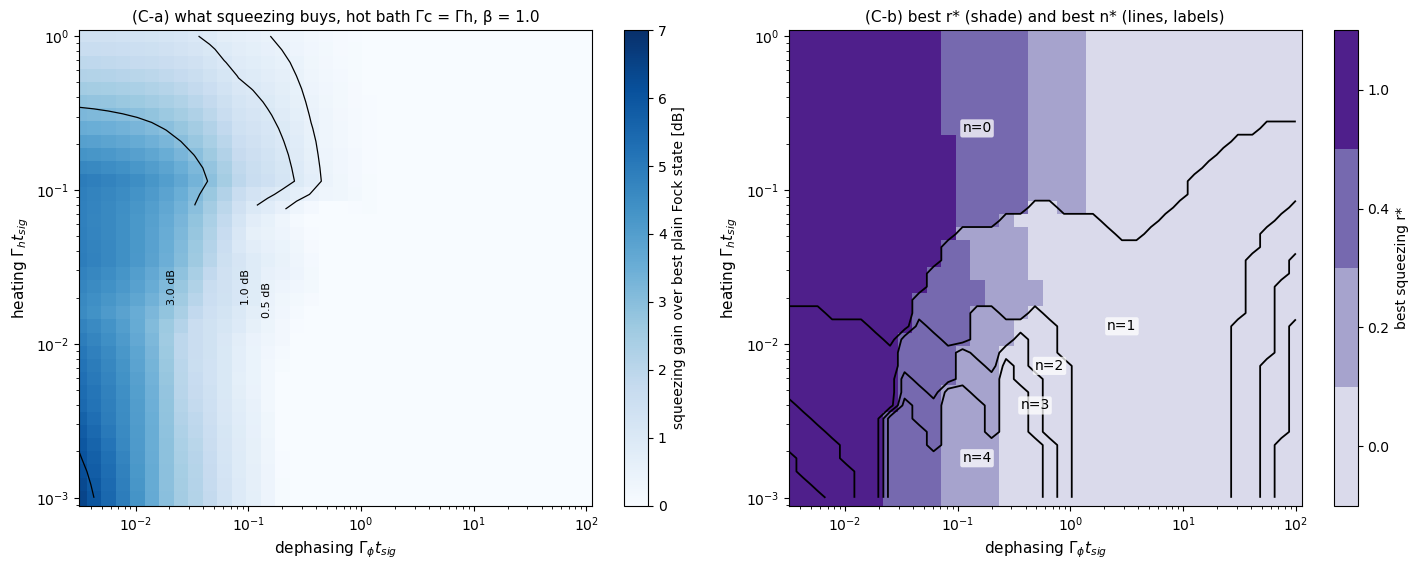

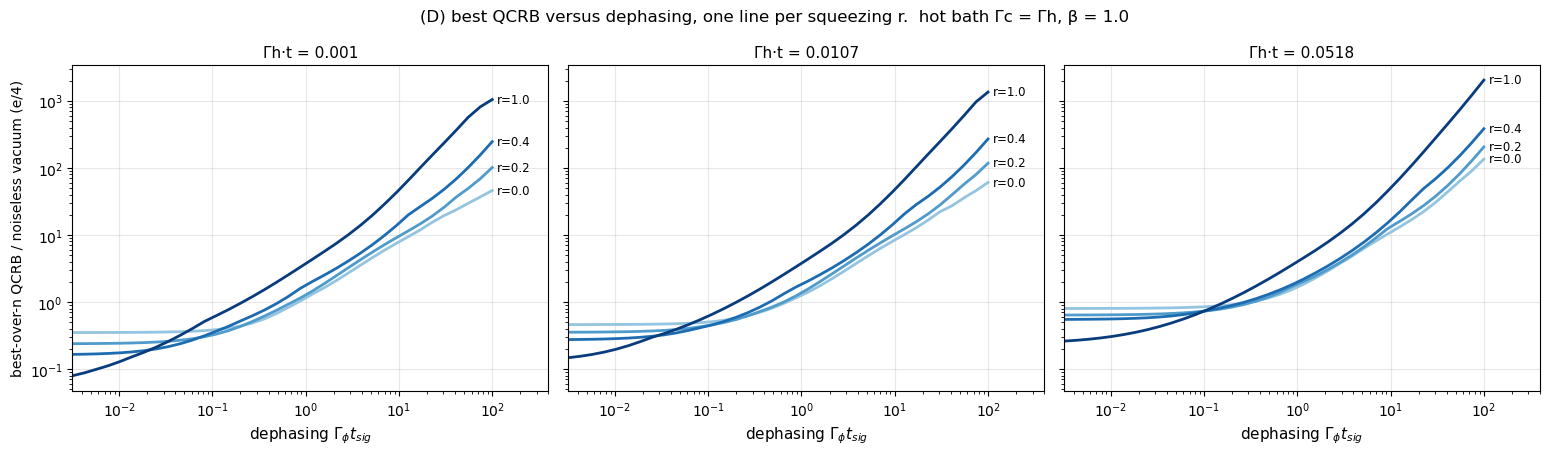

In [8]:
# Figure B: small multiples. One best-n map per fixed r, in the same 1113 colours; the r = 0 boundaries are
# redrawn as dashed lines in every panel, so the shift caused by squeezing is read directly.
function plot_small_multiples(at, mp; file="squeezed_B_small_multiples.png")
    N, R = length(at.n_vals), length(at.r_vals)
    cmap = mcolors.ListedColormap(N_COLORS[1:N])
    fig, axs = subplots(1, R, figsize=(4.3R, 4.6), sharey=true)
    im = nothing
    for j in 1:R
        ax = axs[j]; r = at.r_vals[j]
        im = ax.pcolormesh(at.gps, at.ghs, mp.nstar_r[j, :, :], cmap=cmap, vmin=at.n_vals[1] - 0.5, vmax=at.n_vals[end] + 0.5, shading="nearest")
        if j != mp.j0
            ax.contour(at.gps, at.ghs, mp.nstar_r[mp.j0, :, :], levels=at.n_vals[1:end-1] .+ 0.5, colors="black", linewidths=1.0, linestyles="--")
        end
        setup_axes!(ax, at, @sprintf("r = %.1f", r))
        j > 1 && ax.set_ylabel("")
    end
    cb = fig.colorbar(im, ax=axs, ticks=at.n_vals, fraction=0.02, pad=0.01); cb.set_label("best Fock number n at this r")
    fig.suptitle("(B) best Fock state at each fixed squeezing; dashed: r = 0 boundaries.  $(at.label), β = $(at.β)", fontsize=12)
    savefig(joinpath(PLOT_DIR, file), dpi=130, bbox_inches="tight"); display(fig); close(fig)
end

# Region labels "n = k" at the median position of the cells where n* = k
function label_regions!(ax, at, nmap)
    for n in at.n_vals
        idx = findall(==(n), nmap)
        length(idx) < 6 && continue
        i = round(Int, median(getindex.(idx, 1))); p = round(Int, median(getindex.(idx, 2)))
        ax.text(at.gps[p], at.ghs[i], "n=$n", ha="center", va="center", fontsize=10, color="black",
                bbox=Dict("boxstyle" => "round,pad=0.15", "fc" => "white", "ec" => "none", "alpha" => 0.75))
    end
end

# Figure C: the two questions in separate channels.
#   (a) how much squeezing buys over the best plain Fock state (sequential, one hue, dB)
#   (b) which r achieves it (ordinal, one hue), with the best-n regions drawn as lines and labelled
function plot_decomposed(at, mp; file="squeezed_C_gain_and_rstar.png")
    R = length(at.r_vals)
    fig, (ax1, ax2) = subplots(1, 2, figsize=(14.5, 5.8))
    g = mp.sq_gain
    im1 = ax1.pcolormesh(at.gps, at.ghs, g, cmap="Blues", vmin=0, vmax=ceil(maximum(filter(!isnan, g))), shading="nearest")
    cb1 = fig.colorbar(im1, ax=ax1); cb1.set_label("squeezing gain over best plain Fock state [dB]")
    cs = ax1.contour(at.gps, at.ghs, g, levels=[0.5, 1, 3, 6], colors="black", linewidths=0.9)
    ax1.clabel(cs, fmt="%.1f dB", fontsize=8)
    setup_axes!(ax1, at, "(C-a) what squeezing buys, $(at.label), β = $(at.β)")
    rcols = [PyPlot.matplotlib.cm.Purples(x) for x in range(0.25, 0.9, length=R)]
    rcls = [isnan(v) ? NaN : findfirst(==(v), at.r_vals) for v in mp.rstar]
    im2 = ax2.pcolormesh(at.gps, at.ghs, rcls, cmap=mcolors.ListedColormap(rcols), vmin=0.5, vmax=R + 0.5, shading="nearest")
    cb2 = fig.colorbar(im2, ax=ax2, ticks=1:R); cb2.ax.set_yticklabels(string.(at.r_vals)); cb2.set_label("best squeezing r*")
    ax2.contour(at.gps, at.ghs, mp.nstar, levels=at.n_vals[1:end-1] .+ 0.5, colors="black", linewidths=1.3)
    label_regions!(ax2, at, mp.nstar)
    setup_axes!(ax2, at, "(C-b) best r* (shade) and best n* (lines, labels)")
    tight_layout(); savefig(joinpath(PLOT_DIR, file), dpi=130, bbox_inches="tight"); display(fig); close(fig)
end

# Figure D: line cuts at fixed heating. Here a one-hue light→dark ramp for r works, because lines are
# compared along one axis and each is labelled at its end.
function plot_cuts(at, mp; gh_targets=(1e-3, 1e-2, 5e-2), file="squeezed_D_cuts.png")
    R = length(at.r_vals)
    rcols = [PyPlot.matplotlib.cm.Blues(x) for x in range(0.4, 0.95, length=R)]
    fig, axs = subplots(1, length(gh_targets), figsize=(5.2length(gh_targets), 4.6), sharey=true)
    for (m, gt) in enumerate(gh_targets)
        ax = axs[m]; i = argmin(abs.(log.(at.ghs) .- log(gt)))
        for j in 1:R
            y = mp.best_r[j, i, :] ./ (exp(1) / 4)
            ax.plot(at.gps, y, "-", color=rcols[j], lw=2)
            k = findlast(!isnan, y)
            k === nothing || ax.text(at.gps[k] * 1.12, y[k], "r=$(at.r_vals[j])", fontsize=8.5, va="center")
        end
        ax.set_xscale("log"); ax.set_yscale("log"); ax.grid(alpha=0.3)
        ax.set_xlim(at.gps[1], at.gps[end] * 4)
        ax.set_xlabel(L"dephasing $\Gamma_\phi t_{sig}$", fontsize=11)
        ax.set_title(@sprintf("Γh·t = %.3g", at.ghs[i]), fontsize=11)
    end
    axs[1].set_ylabel("best-over-n QCRB / noiseless vacuum (e/4)", fontsize=10)
    fig.suptitle("(D) best QCRB versus dephasing, one line per squeezing r.  $(at.label), β = $(at.β)", fontsize=12)
    tight_layout(); savefig(joinpath(PLOT_DIR, file), dpi=130, bbox_inches="tight"); display(fig); close(fig)
end

using Statistics: median
plot_small_multiples(at, mp)
plot_decomposed(at, mp)
plot_cuts(at, mp)

In [9]:
# Numbers behind the figures
function summarize(at, mp)
    valid = .!at.bad; N, R = length(at.n_vals), length(at.r_vals)
    println("share of the map won by each (n, r):")
    @printf("%6s", ""); for r in at.r_vals; @printf("  r=%-5.1f", r); end; println()
    for (k, n) in enumerate(at.n_vals)
        @printf("  n=%d ", n)
        for j in 1:R
            @printf("  %5.1f%%", 100 * count(==((k - 1) * R + j), mp.cls[valid]) / count(valid))
        end
        println()
    end
    g = mp.sq_gain[valid]
    @printf("squeezing gain over best plain Fock state: median %.2f dB, max %.2f dB, < 0.5 dB on %.0f%% of the map\n",
            median(g), maximum(g), 100 * count(<(0.5), g) / length(g))
    rmax = maximum(at.r_vals)
    @printf("best r* = r_max (%.1f) on %.0f%% of the map; interior optimum (0 < r* < r_max) on %.0f%%; r* = 0 on %.0f%%\n",
            rmax, 100 * count(==(rmax), mp.rstar[valid]) / count(valid),
            100 * count(x -> 0 < x < rmax, mp.rstar[valid]) / count(valid), 100 * count(==(0.0), mp.rstar[valid]) / count(valid))
    changed = count(mp.nstar_r[mp.j0, :, :][valid] .!= mp.nstar[valid])
    @printf("best n changes once squeezing is allowed on %.0f%% of the map\n", 100 * changed / count(valid))
end
summarize(at, mp)

share of the map won by each (n, r):
        r=0.0    r=0.2    r=0.4    r=1.0  
  n=0    13.1%    4.2%    6.2%   18.9%
  n=1    24.7%    2.2%    1.9%    5.9%
  n=2     6.0%    0.8%    1.2%    1.7%
  n=3     3.3%    0.8%    0.7%    0.5%
  n=4     3.4%    2.4%    1.9%    0.0%
squeezing gain over best plain Fock state: median 0.00 dB, max 6.44 dB, < 0.5 dB on 61% of the map
best r* = r_max (1.0) on 27% of the map; interior optimum (0 < r* < r_max) on 22%; r* = 0 on 51%
best n changes once squeezing is allowed on 25% of the map


## 7. Strong-dephasing zoom: where higher Fock states come back

The atlas above does contain the high-dephasing return of higher Fock states (1121_dephasing_reentrance): at Γh·t = 0.001 the best state is |2⟩ at Γφt = 41 and |4⟩ at Γφt = 100, both with r = 0. It is easy to miss for four reasons:
1. The dephasing axis stops at Γφt = 100. At β = 1 the return only starts near Γφt ≈ 4β²/0.117 ≈ 34.
2. The return survives only for Γh·t ≲ 0.05, the bottom of a heating axis that runs up to 1.
3. n was capped at 4.
4. These cells have r = 0, so Figure A draws them in its palest shades, which are the hardest to tell apart.

This zoom covers Γφt = 1–500 and Γh·t = 10⁻³–0.1 with n ≤ 5. r = 1 is left out because it never wins at Γφt > 1.4 in the full atlas (printed below), and leaving it out keeps the cutoff at 61 levels.

full atlas, Γφt > 1.4: r* = 0 on 100.0% of points, r* = 1 on 0.0%
hot bath Γc = Γh, β = 1.00: 24 × 24 points × 18 states in 328 s; 0 points dropped at the Fock cutoff
zoom: r* = 0 on 99.3% of points; max squeezing gain 0.13 dB
  n = 1 wins at Γφt > 30 up to Γh·t = 0.100
  n = 2 wins at Γφt > 30 up to Γh·t = 0.100
  n = 3 wins at Γφt > 30 up to Γh·t = 0.055
  n = 4 wins at Γφt > 30 up to Γh·t = 0.045
  n = 5 wins at Γφt > 30 up to Γh·t = 0.030


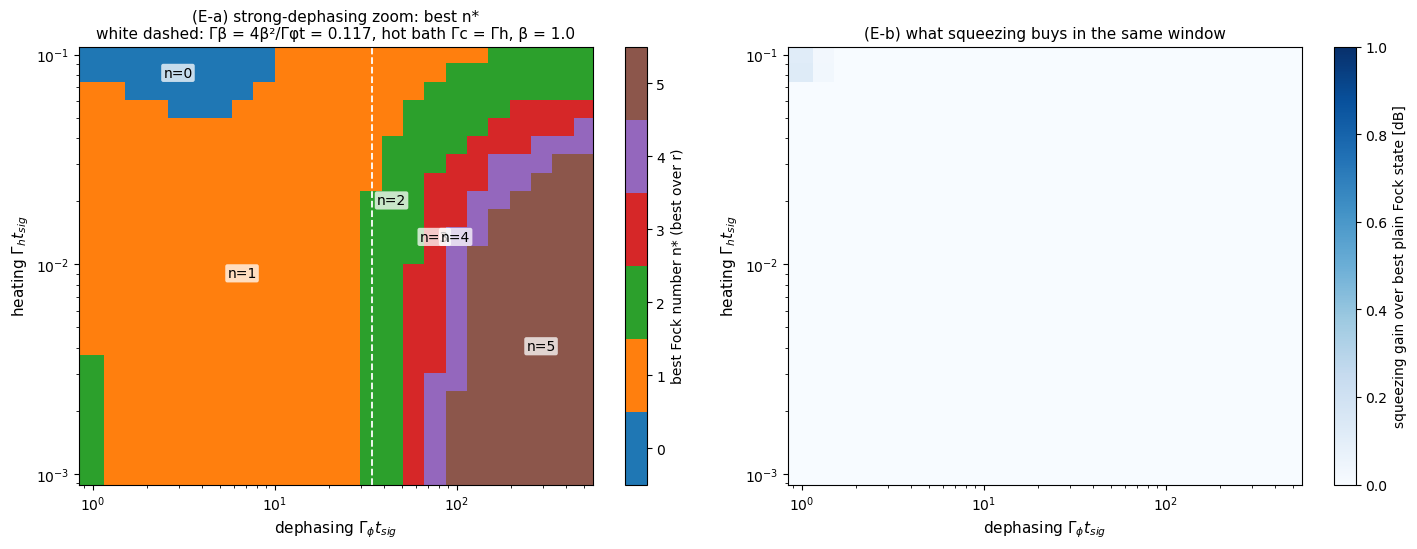

In [10]:
let sel = at.gps .> 1.4
    @printf("full atlas, Γφt > 1.4: r* = 0 on %.1f%% of points, r* = 1 on %.1f%%\n",
            100 * count(==(0.0), mp.rstar[:, sel]) / count(!isnan, mp.rstar[:, sel]),
            100 * count(==(1.0), mp.rstar[:, sel]) / count(!isnan, mp.rstar[:, sel]))
end
atz = squeezed_atlas(β=1.0, Gc=0.0, thermal=true, n_vals=collect(0:5), r_vals=[0.0, 0.2, 0.4],
                     grid=24, gphi_range=(1.0, 500.0), gh_range=(1e-3, 0.1))
mpz = atlas_maps(atz)

fig, (ax1, ax2) = subplots(1, 2, figsize=(14.5, 5.6))
im1 = ax1.pcolormesh(atz.gps, atz.ghs, mpz.nstar, cmap=mcolors.ListedColormap(N_COLORS[1:6]), vmin=-0.5, vmax=5.5, shading="nearest")
cb1 = fig.colorbar(im1, ax=ax1, ticks=0:5); cb1.set_label("best Fock number n* (best over r)")
ax1.axvline(4atz.β^2 / 0.117, color="white", ls="--", lw=1.3)          # effective drive bath Γβ = 0.117
label_regions!(ax1, atz, mpz.nstar)
setup_axes!(ax1, atz, "(E-a) strong-dephasing zoom: best n*\nwhite dashed: Γβ = 4β²/Γφt = 0.117, $(atz.label), β = $(atz.β)")
g = mpz.sq_gain
im2 = ax2.pcolormesh(atz.gps, atz.ghs, g, cmap="Blues", vmin=0, vmax=max(1.0, ceil(maximum(filter(!isnan, g)))), shading="nearest")
cb2 = fig.colorbar(im2, ax=ax2); cb2.set_label("squeezing gain over best plain Fock state [dB]")
setup_axes!(ax2, atz, "(E-b) what squeezing buys in the same window")
tight_layout(); savefig(joinpath(PLOT_DIR, "squeezed_E_strong_dephasing_zoom.png"), dpi=130, bbox_inches="tight"); display(fig); close(fig)

valid = .!atz.bad
@printf("zoom: r* = 0 on %.1f%% of points; max squeezing gain %.2f dB\n", 100 * count(==(0.0), mpz.rstar[valid]) / count(valid), maximum(g[valid]))
for n in 1:5
    rows = [i for i in eachindex(atz.ghs) if any(mpz.nstar[i, atz.gps .> 30] .== n)]
    isempty(rows) ? @printf("  n = %d never wins at Γφt > 30\n", n) : @printf("  n = %d wins at Γφt > 30 up to Γh·t = %.3f\n", n, atz.ghs[maximum(rows)])
end

## 8. Results (hot bath Γc = Γh, β = 1, n ≤ 4, r ∈ {0, 0.2, 0.4, 1})

- **Squeezing helps only at weak dephasing.** The gain over the best plain Fock state reaches 6.4 dB at Γφt ~ 10⁻³–10⁻², drops below 1 dB near Γφt ≈ 0.1, and is zero beyond Γφt ≈ 1 (r* = 0 on 51% of the map). Reason: a squeezed state is spread over many number states, and dephasing destroys the coherences between number states at a rate ∝ (j − k)², so the spread state loses more.
- **Higher Fock states come back at strong dephasing, without squeezing** (zoom, Figure E). The best n climbs 1 → 2 → 3 → 4 → 5 as Γφt grows past ≈ 34 (where Γβ = 0.117). n = 5 wins up to Γh·t ≈ 0.03, n = 3 up to 0.055, n = 2 up to 0.1. In this window r* = 0 on 99% of points, and squeezing buys at most 0.13 dB. Mechanism and Wigner snapshots: `1121_dephasing_reentrance.ipynb`, P3–P7.
- **Squeezing and Fock number substitute for each other.** With squeezing allowed, the best n drops: at r = 1 the vacuum wins almost everywhere, while at r = 0 it is |4⟩ at weak noise (Figure B). The best state changes on 25% of the map.
- **Heating does not remove the squeezing benefit.** In a hot bath B = 2Γh t + e^{−2r}, so squeezing still reduces the variance. Its gain persists up to Γh·t ≈ 0.3 at weak dephasing (Figure C-a, the 3 dB contour).
- **Resources.** S(1)|4⟩ has ⟨n̂⟩ = 16.4, against 4 for |4⟩. This atlas compares states at fixed r, not at equal energy. An equal-⟨n̂⟩ comparison is the natural next step before claiming squeezing beats Fock states.
- **Numerics.** The engine matches eq. 33/106 for squeezed states to ≤ 5e-6. The cutoff is chosen per r (r = 1 needs 141 levels; 61 would have produced fake QCRB values 3× too low). No grid points were dropped at the cutoff.